# Customer Churn Prediction: Improved Version
**Author:** Mohammad Aqel · **Dataset:** Iranian Churn Dataset, UCI ML Repository ([doi 10.24432/C5JW3Z](https://doi.org/10.24432/C5JW3Z))

**The story in one line:** my first model (CSC61304 Assignment 3) showed **90% accuracy**, but it **missed about half of the customers who actually left**. This notebook explains why, and fixes it.

| Part | What it does |
|---|---|
| 0–2 | Setup, load, clean, split (same as the original project) |
| 3 | The accuracy trap: compare with a model that always says "no churn" |
| 4 | Correlation check: why the old coefficients looked strange |
| 5 | Compare 4 models fairly with 5-fold cross-validation |
| 6 | Tune the decision threshold so we catch more churners |
| 7 | Final test: old model vs new model |
| 8 | What drives churn? (permutation importance) |
| 9 | Summary and limitations |
| 10 | Your turn: small changes and Python exercises |

**Golden rule used in this notebook:** the test set is used **only once**, in Part 7. Every choice (which model, which threshold) is made using the training data only. If we used the test set to make choices, the final score would be too optimistic.

## Part 0: Setup
### 0.1 Upload the dataset (Google Colab)
Run the cell and choose `Customer Churn.csv`. When running locally, put the CSV in the same folder.

**Python note:** `try / except ImportError` means: *try* the Colab code; if Python can't import `google.colab` (because we're not in Colab), run the `except` part instead. The notebook works in both places.

In [1]:
# Part 0.1: Upload the CSV (Colab only)
try:
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]
except ImportError:
    CSV_PATH = "Customer Churn.csv"
print("Using file:", CSV_PATH)

Saving Customer Churn.csv to Customer Churn.csv
Using file: Customer Churn.csv


### 0.2 Imports and chart style
**What's new compared with the original notebook:**
- `make_pipeline`: joins the scaler and the model into one object (explained in Part 3).
- `StratifiedKFold`, `cross_validate`, `cross_val_predict`: tools for cross-validation (Part 5–6).
- `DummyClassifier`, `RandomForestClassifier`, `HistGradientBoostingClassifier`: new models to compare against.
- `precision_recall_curve`, `average_precision_score`, `roc_auc_score`: metrics that use **probabilities**, not just 0/1 predictions.
- `permutation_importance`: to find which features matter most (Part 8).

**Python note:** `import numpy as np` gives the library a short nickname. Everyone uses `np` and `pd`, so other people can read your code easily.

The `plt.rcParams.update({...})` line sets the chart style once for the whole notebook, so we don't repeat the same settings in every chart.

In [2]:
# Part 0.2: Imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, precision_recall_curve,
                             confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)

# One chart style for the whole notebook
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": GREY, "font.size": 10,
})
os.makedirs("figures", exist_ok=True)   # folder for saved charts
RANDOM_STATE = 42                       # one number used everywhere, for reproducible results

## Part 1: Load and clean
This is the same cleaning as the original project: remove the 300 exact duplicate rows, then tidy the column names.

**Why remove duplicates before splitting?** If the same customer row appears in both the training set and the test set, the model has already "seen" a test answer. Removing duplicates first prevents this (it's a form of **data leakage**).

**Python note: the list comprehension**
```python
[col.strip().replace("  ", " ").replace(" ", "_") for col in df.columns]
```
reads as: *for each `col` in the column names, clean it, and collect the results in a new list.* It's a short way of writing a `for` loop that builds a list. The methods are **chained**: `.strip()` removes spaces at the ends, then the first `.replace()` turns double spaces into single spaces, then the second turns spaces into `_`.

In [3]:
# Part 1: Load, remove duplicates, clean column names
df = pd.read_csv(CSV_PATH)
print("Shape before cleaning:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
df.columns = [col.strip().replace("  ", " ").replace(" ", "_") for col in df.columns]

print("Shape after cleaning:", df.shape)
print("Churn rate: {:.2%}".format(df["Churn"].mean()))

Shape before cleaning: (3150, 14)
Duplicate rows: 300
Shape after cleaning: (2850, 14)
Churn rate: 15.65%


**Python note: `df["Churn"].mean()`.** Churn contains only 0s and 1s, so its average is the **share of 1s**, which is the churn rate. This is a useful trick for any yes/no column.

**Important fact about this dataset (from the UCI page):** all features are totals from the **first 9 months**, and churn is measured at the **end of month 12**. So the model predicts churn **3 months ahead**, which gives the company time to act. It also means the features don't "contain the answer" (no time leakage).

## Part 2: Features, target and split
Same 80/20 split as the original, with `stratify=y`.

**Why `stratify=y`?** Only about 16% of customers churn. Without stratify, the test set could get 12% or 20% churners just by luck. With stratify, both sets keep the same 15.6% churn rate, so the comparison is fair.

**Python note:** `df.drop(columns=["Churn"])` returns a **new** table without the Churn column. It doesn't change `df` itself. `X` (capital) holds the features, `y` (small) is the target. That's the standard naming in ML.

In [4]:
# Part 2: Split into features (X) and target (y), then 80/20
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| churners:", y_train.sum())
print("Test :", X_test.shape,  "| churners:", y_test.sum())

Train: (2280, 13) | churners: 357
Test : (570, 13) | churners: 89


## Part 3: The accuracy trap
**Question:** is 90% accuracy actually good?

To find out, we compare against the **dumbest possible model**: one that always says *"no churn"*. Real ML teams always start with a baseline like this. If your model can't clearly beat it, the model is useless.

We also rebuild the **original Logistic Regression**, to compare against later.

**What's new: `make_pipeline(StandardScaler(), LogisticRegression(...))`**
- A **pipeline** joins several steps into one object. When you call `.fit()`, it fits the scaler on the training data, scales it, then trains the model. When you call `.predict()`, it scales the new data with the *same* scaler, then predicts.
- It gives **exactly the same result** as your original code (scaler fitted on train only).
- **Why use it?** In Part 5 we use cross-validation, which splits the training data 5 times. The scaler must be refitted inside each split, or information leaks from the validation part. A pipeline does this automatically. Doing it by hand would be long and easy to get wrong.

**Python note: functions (`def`)**. `show_scores` is a small function we write once and call 3 times. This avoids copying the same 3 lines everywhere (a good habit called *DRY: Don't Repeat Yourself*). In the f-string, `{name:<38}` means "left-align the name in 38 characters", so the columns line up.

`zero_division=0` tells sklearn: if the model never predicts churn, set precision to 0 instead of showing a warning.

In [5]:
# Part 3: Dumb baseline vs the original Logistic Regression
def show_scores(name, y_true, y_pred):
    print(f"{name:<38} accuracy {accuracy_score(y_true, y_pred):.3f} | "
          f"recall {recall_score(y_true, y_pred, zero_division=0):.3f} | "
          f"precision {precision_score(y_true, y_pred, zero_division=0):.3f}")

# 1) Always predicts the most common class (= "no churn")
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
show_scores("Dummy (always 'no churn')", y_test, dummy.predict(X_test))

# 2) The original model, rebuilt as a pipeline (same result as the old notebook)
old_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
old_lr.fit(X_train, y_train)
show_scores("Original Logistic Regression", y_test, old_lr.predict(X_test))

Dummy (always 'no churn')              accuracy 0.844 | recall 0.000 | precision 0.000
Original Logistic Regression           accuracy 0.904 | recall 0.483 | precision 0.827


**What this shows:**
- The dummy model gets **~84% accuracy** while catching **zero** churners. So 84% is the "free" score, and our 90% is only 6 points better than doing nothing.
- The dummy's recall is exactly 0 because it never predicts churn, so it can't catch any churner.
- **Lesson:** with imbalanced data (few churners), **accuracy is misleading**. From now on we focus on **recall** (how many churners we catch), **precision** (how many of our alarms are real), and **PR-AUC** (explained in Part 5).

## Part 4: Correlation check: why the old coefficients looked strange
In the original report, `Seconds_of_Use` had a **positive** coefficient (+0.98: more calling time → more churn?) while `Frequency_of_use` had a strong **negative** one (−2.14). That doesn't make business sense. The usual cause is **multicollinearity**: two features that carry almost the same information.

When two features are almost copies of each other, Logistic Regression can split their effect in strange ways (one big positive, one big negative) and the predictions stay the same. The **predictions** are fine, but the **coefficients** can't be trusted for explanations.

**What the code does:**
1. `X_train.corr()` builds a 13×13 table of correlations (−1 to +1) between every pair of features. We use training data only (golden rule).
2. Draw it as a heatmap.
3. Loop over the table and list pairs with |correlation| > 0.7.

**Python notes:**
- `corr.iloc[i, j]` gets a value by **position** (row i, column j). `.loc` would use **names** instead.
- The double loop `for j in range(i + 1, n)` starts at `i + 1`, so each pair is checked only once (A–B, not also B–A) and we skip a feature against itself (always 1.0).
- `abs(r)` because a strong **negative** correlation is just as strong as a positive one.

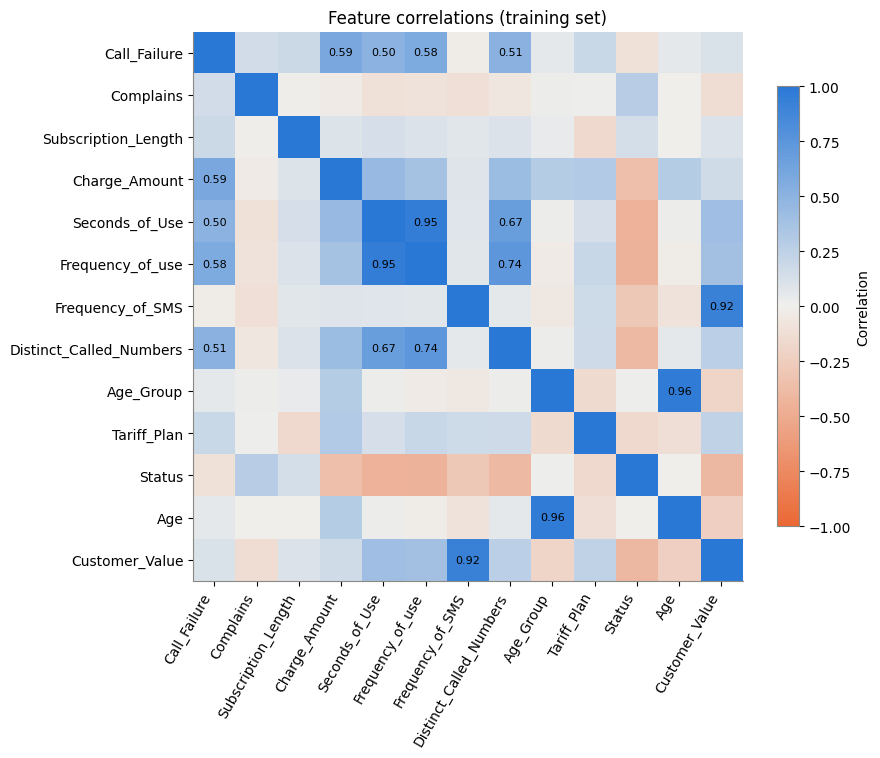

,Feature A,Feature B,Correlation
0,Seconds_of_Use,Frequency_of_use,0.946
1,Frequency_of_use,Distinct_Called_Numbers,0.735
2,Frequency_of_SMS,Customer_Value,0.921
3,Age_Group,Age,0.962


In [6]:
# Part 4.1: Correlation heatmap (training data only)
corr = X_train.corr()

diverging = LinearSegmentedColormap.from_list("div", [ORANGE, "#f0efec", BLUE])
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if i != j and abs(corr.iloc[i, j]) >= 0.5:      # label only the strong cells
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8, label="Correlation")
ax.set_title("Feature correlations (training set)")
plt.tight_layout()
plt.savefig("figures/correlation_heatmap.png", dpi=150)
plt.show()

# Part 4.2: List the strongly correlated pairs
strong_pairs = []
n = len(corr.columns)
for i in range(n):
    for j in range(i + 1, n):
        r = corr.iloc[i, j]
        if abs(r) > 0.7:
            strong_pairs.append((corr.columns[i], corr.columns[j], round(r, 3)))

display(pd.DataFrame(strong_pairs, columns=["Feature A", "Feature B", "Correlation"]))

**Three pairs are almost duplicates (r > 0.9):**
- `Seconds_of_Use` ↔ `Frequency_of_use` (0.95): more calls means more call time.
- `Age_Group` ↔ `Age` (0.96): age group is just age put into bins.
- `Customer_Value` ↔ `Frequency_of_SMS` (0.92): the value formula seems to depend mostly on SMS use.

**Fix for the Logistic Regression explanation:** keep one feature from each pair and drop the other: `Seconds_of_Use`, `Age_Group`, `Customer_Value`.
- We keep `Frequency_of_use` and `Age` because they're simple to explain.
- We drop `Customer_Value` because the dataset doesn't say how it's calculated.

Then we check two things:
1. Do the coefficients now make sense?
2. Did we lose any predictive power? We check this with cross-validation on the **training set**, not the test set.

**Python notes:**
- `pd.Series(values, index=names)` attaches a name to each number. When two Series are put into one DataFrame, pandas **matches them by name**. That's why the dropped features show `NaN` (= empty) in the 10-feature column.
- `old_lr[-1]` gets the **last step** of the pipeline (the LogisticRegression), and `.coef_[0]` gets its coefficients.

In [7]:
# Part 4.3: Logistic Regression with vs without the redundant features
redundant = ["Seconds_of_Use", "Age_Group", "Customer_Value"]
X_train_small = X_train.drop(columns=redundant)

lr_small = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
lr_small.fit(X_train_small, y_train)

coef_compare = pd.DataFrame({
    "All 13 features": pd.Series(old_lr[-1].coef_[0], index=X_train.columns),
    "10 features":     pd.Series(lr_small[-1].coef_[0], index=X_train_small.columns),
}).round(2).sort_values("All 13 features")
display(coef_compare)

# Did we lose predictive power? 5-fold CV on the training set (PR-AUC, explained in Part 5)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for label, data in [("13 features", X_train), ("10 features", X_train_small)]:
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    scores = cross_validate(model, data, y_train, cv=cv, scoring="average_precision")
    print(f"{label}: CV PR-AUC = {scores['test_score'].mean():.3f}")

,All 13 features,10 features
Frequency_of_use,-2.14,-1.33
Frequency_of_SMS,-1.39,-1.31
Charge_Amount,-0.76,-0.59
Distinct_Called_Numbers,-0.41,-0.40
Subscription_Length,-0.23,-0.22
Age,-0.10,-0.05
Tariff_Plan,0.01,-0.03
Age_Group,0.04,NaN
Customer_Value,0.08,NaN
Status,0.46,0.44


13 features: CV PR-AUC = 0.754
10 features: CV PR-AUC = 0.748


**Result:**
- After dropping the copies, `Frequency_of_use` shrinks from −2.14 to about −1.3, and the confusing positive `Seconds_of_Use` effect disappears. The coefficients are now easier to trust.
- Predictive power is almost **unchanged** (CV PR-AUC 0.754 → 0.748). The dropped features added no new information, only confusion.
- The clearest signals are: **complaints** and **call failures** raise churn risk; **using the service more** (calls, SMS) lowers it.

**Why not drop features for the tree models too?** Tree models (Part 5) don't have coefficients and aren't confused in the same way, so we give them all 13 features.

**Why `cv` is created here:** `StratifiedKFold(n_splits=5, shuffle=True, ...)` describes *how* to split the training data into 5 parts, each with the same churn rate. We reuse the same `cv` object in Parts 5 and 6, so every model is tested on exactly the same splits (a fair comparison).

## Part 5: Compare 4 models fairly (5-fold cross-validation)
**Cross-validation** splits the training set into 5 parts. Each model trains on 4 parts and is scored on the 5th, five times, so every part gets to be the "exam" once. We report the **average**. This is more reliable than a single split and **doesn't touch the test set**.

**The 4 models:**
| Model | Why include it |
|---|---|
| Logistic Regression (original) | the starting point |
| Logistic Regression + `class_weight="balanced"` | the simplest fix for imbalance: each churner counts ~5× more during training |
| Random Forest | many decision trees voting; can learn non-linear rules (e.g. "complaint AND low usage") |
| Gradient Boosting (`HistGradientBoostingClassifier`) | trees built one after another, each fixing the previous one's mistakes; usually the strongest on table data |

**Why `HistGradientBoostingClassifier` and not XGBoost?** It's the same family of model (gradient-boosted trees) and is built into scikit-learn, so no extra install is needed. XGBoost would give very similar results here.

**Why not SMOTE (creating fake churners)?** It invents synthetic customers. It must be done very carefully inside cross-validation, and on this kind of data it rarely beats class weights or threshold tuning. Simpler is better.

**The main metric is PR-AUC (average precision).**
- It summarises the **precision–recall trade-off over every possible threshold** and focuses on the churners.
- A random model scores ≈ 0.16 (the churn rate) and a perfect one scores 1.0.
- **Why not ROC-AUC?** When churners are rare, ROC-AUC can look high even for an average model, because it counts the many easy "no churn" customers. We show it too, but PR-AUC is more honest here.
- Recall and precision in the table use the default threshold of 0.5.

**Python notes:**
- `models` is a **dictionary**: `{name: model}`. `models.items()` gives `(name, model)` pairs, which we unpack in `for name, model in ...`.
- We collect one **dictionary per model** in a list (`rows`), then turn the list into a DataFrame. This is a very common pandas pattern.
- `scores[f"test_{metric}"]` gives an array of 5 numbers (one per fold), and `.mean()` averages them.

In [8]:
# Part 5: Cross-validated comparison on the training set
models = {
    "Logistic Regression (original)": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Logistic Regression + class weights": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
scoring = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "Recall": "recall", "Precision": "precision"}

rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()
    row["PR-AUC (std)"] = scores["test_PR-AUC"].std()
    rows.append(row)

cv_results = pd.DataFrame(rows).set_index("Model").sort_values("PR-AUC", ascending=False).round(3)
display(cv_results)

best_name = cv_results.index[0]          # first row = highest PR-AUC
best_model = models[best_name]
print("Best model by cross-validated PR-AUC:", best_name)

,PR-AUC,ROC-AUC,Recall,Precision,PR-AUC (std)
Model,,,,,
Gradient Boosting,0.948,0.986,0.837,0.903,0.018
Random Forest,0.921,0.983,0.790,0.893,0.034
Logistic Regression (original),0.754,0.933,0.468,0.781,0.021
Logistic Regression + class weights,0.749,0.934,0.863,0.501,0.022


Best model by cross-validated PR-AUC: Gradient Boosting


**What this table teaches (key insight of the project):**
1. **Class weights helped recall but not the model.** Logistic Regression + class weights catches far more churners, but precision falls to about 0.5 (half the alarms are false), and **PR-AUC doesn't change**. Class weights and thresholds only **move along the same trade-off curve**. To do better on *both* recall and precision, you need a **better model**.
2. **The tree models are much better.** PR-AUC rises from ~0.75 to ~0.95. Churn here depends on combinations of features, which a straight-line model like Logistic Regression can't capture.
3. Gradient Boosting wins, and its small std (±0.02) shows that the result is stable across the 5 folds, not luck.

**Model choice:** Gradient Boosting, picked by **training-data cross-validation**, not by the test set.

## Part 6: Tune the decision threshold
A model gives each customer a **probability of churn** (e.g. 0.31). By default, sklearn says "churn" when the probability is ≥ 0.5. But 0.5 is just a convention. For churn, **missing a churner usually costs more than a false alarm**: a retention offer is cheap, a lost customer is expensive. So a lower threshold can make sense.

**How we choose it, without touching the test set:**
1. `cross_val_predict(..., method="predict_proba")` gives an **out-of-fold** probability for each training customer: each customer is predicted by a model that **didn't** train on them, so the probabilities are honest.
2. `precision_recall_curve` calculates precision and recall at every possible threshold.
3. We pick the threshold with the **highest F1** (the balance of precision and recall).

**Why F1?** It's a neutral rule when we don't know the real business costs. If a company told us "we must catch at least 95% of churners", we'd use that rule instead (see the exercises in Part 10).

**Python notes:**
- `predict_proba` returns 2 columns: P(no churn) and P(churn). `[:, 1]` means "all rows, column 1", which keeps only P(churn). This is **NumPy slicing**.
- `precision` and `recall` have **one more value** than `thresholds` (sklearn adds a final point). That's why we use `f1[:-1]`, which means "all except the last".
- `+ 1e-12` avoids dividing by zero when precision and recall are both 0.
- `np.argmax(f1)` returns the **position** of the biggest value, not the value itself.

In [9]:
# Part 6.1: Out-of-fold probabilities on the training set
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_proba)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best_idx = np.argmax(f1[:-1])
best_threshold = thresholds[best_idx]

print(f"Chosen threshold: {best_threshold:.3f}")
print(f"On training CV -> precision {precision[best_idx]:.3f}, recall {recall[best_idx]:.3f}, F1 {f1[best_idx]:.3f}")

Chosen threshold: 0.189
On training CV -> precision 0.857, recall 0.924, F1 0.889


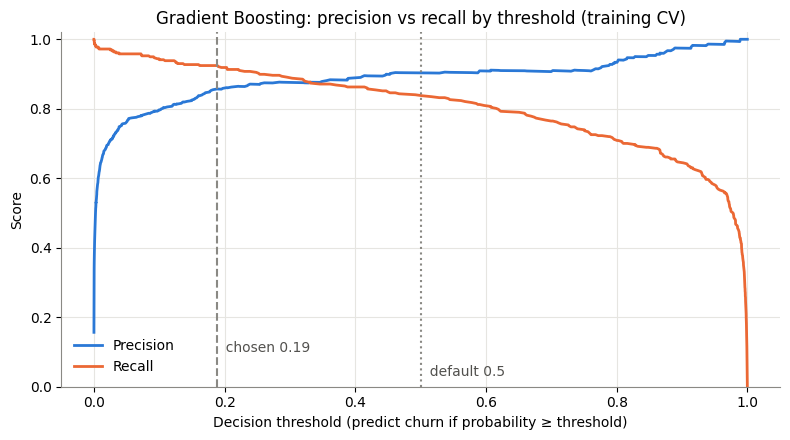

In [10]:
# Part 6.2: Precision and recall at every threshold
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds, precision[:-1], color=BLUE, linewidth=2, label="Precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, linewidth=2, label="Recall")
ax.axvline(0.5, color=GREY, linestyle=":", linewidth=1.5)
ax.axvline(best_threshold, color=GREY, linestyle="--", linewidth=1.5)
ax.text(0.5, 0.03, "  default 0.5", color="#52514e")
ax.text(best_threshold, 0.10, f"  chosen {best_threshold:.2f}", color="#52514e")
ax.set_xlabel("Decision threshold (predict churn if probability ≥ threshold)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.set_title(f"{best_name}: precision vs recall by threshold (training CV)")
ax.legend(loc="lower left", frameon=False)
plt.tight_layout()
plt.savefig("figures/threshold_tuning.png", dpi=150)
plt.show()

**Reading the chart:** moving the threshold **left** (lower) catches more churners (recall ↑) but raises more false alarms (precision ↓). Around the chosen value, recall rises a lot while precision falls only a little, so that's a good trade.

## Part 7: Final test (the test set is used only here)
Now we:
1. train the chosen model on the **full** training set,
2. predict probabilities for the test set,
3. apply the chosen threshold,
4. compare everything in one table.

**Python notes:**
- `test_proba >= best_threshold` compares every value with the threshold and gives an array of `True`/`False`. `.astype(int)` turns it into 1/0, which are our predictions.
- `confusion_matrix(...).ravel()` flattens the 2×2 matrix into 4 numbers in the order **TN, FP, FN, TP**. We **unpack** them into 4 variables in one line.
- `evaluate()` is a function that returns a **dictionary**, so each call becomes one row of the results table.

In [11]:
# Part 7.1: Train the chosen model on all training data, then predict the test set
best_model.fit(X_train, y_train)
new_proba = best_model.predict_proba(X_test)[:, 1]
old_proba = old_lr.predict_proba(X_test)[:, 1]

def evaluate(name, y_true, proba, threshold):
    y_pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"Model": name, "Threshold": threshold,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "PR-AUC": average_precision_score(y_true, proba),
            "ROC-AUC": roc_auc_score(y_true, proba),
            "Churners caught": tp, "Churners missed": fn, "False alarms": fp}

dummy_proba = dummy.predict_proba(X_test)[:, 1]
final_table = pd.DataFrame([
    evaluate("Dummy (always 'no churn')", y_test, dummy_proba, 0.5),
    evaluate("Original Logistic Regression", y_test, old_proba, 0.5),
    evaluate(f"{best_name} (threshold 0.5)", y_test, new_proba, 0.5),
    evaluate(f"{best_name} (tuned threshold)", y_test, new_proba, best_threshold),
]).set_index("Model").round(3)
display(final_table)

,Threshold,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,Churners caught,Churners missed,False alarms
Model,,,,,,,,,,
Dummy (always 'no churn'),0.500,0.844,0.000,0.000,0.000,0.156,0.500,0,89,0
Original Logistic Regression,0.500,0.904,0.827,0.483,0.610,0.760,0.927,43,46,9
Gradient Boosting (threshold 0.5),0.500,0.963,0.905,0.854,0.879,0.958,0.990,76,13,8
Gradient Boosting (tuned threshold),0.189,0.961,0.853,0.910,0.880,0.958,0.990,81,8,14


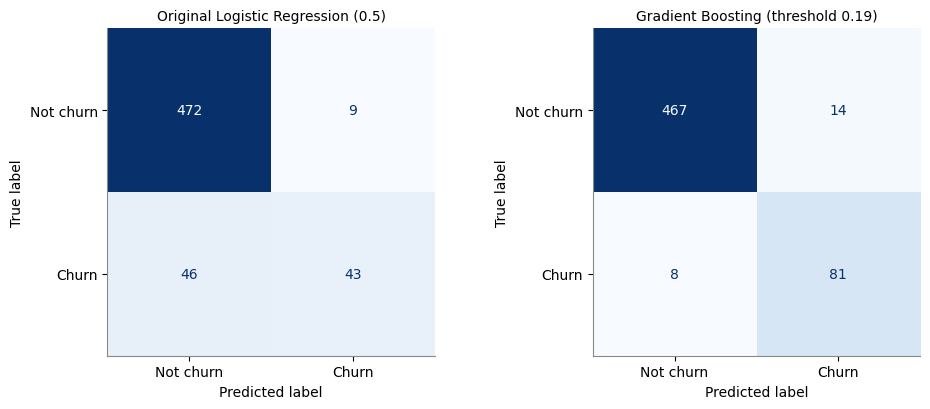

In [12]:
# Part 7.2: Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
pairs = [("Original Logistic Regression (0.5)", (old_proba >= 0.5).astype(int)),
         (f"{best_name} (threshold {best_threshold:.2f})", (new_proba >= best_threshold).astype(int))]
for ax, (title, y_pred) in zip(axes, pairs):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Not churn", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title, fontsize=10)
    ax.grid(False)
plt.tight_layout()
plt.savefig("figures/confusion_matrices.png", dpi=150)
plt.show()

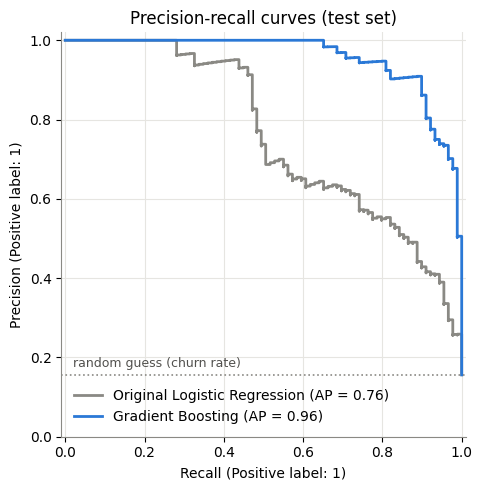

In [13]:
# Part 7.3: Precision-recall curves on the test set
fig, ax = plt.subplots(figsize=(6.5, 5))
PrecisionRecallDisplay.from_predictions(y_test, old_proba, ax=ax, color=GREY, linewidth=2,
                                        name="Original Logistic Regression")
PrecisionRecallDisplay.from_predictions(y_test, new_proba, ax=ax, color=BLUE, linewidth=2,
                                        name=best_name)
ax.axhline(y_test.mean(), color=GREY, linestyle=":", linewidth=1.2)
ax.text(0.02, y_test.mean() + 0.02, "random guess (churn rate)", color="#52514e", fontsize=9)
ax.set_ylim(0, 1.02)
ax.set_title("Precision-recall curves (test set)")
ax.legend(loc="lower left", frameon=False)
plt.tight_layout()
plt.savefig("figures/pr_curves.png", dpi=150)
plt.show()

**Result:**
- The original model **missed 46 of the 89 churners**. The final model misses **only 8**, while keeping precision high (about 85% of alarms are real churners).
- Accuracy also improves, but that is not the main point anymore: the real gain is in **catching churners**.
- The PR curve shows that the new model is better at **every** threshold, not just the one we picked.
- The test results are close to the cross-validation results from Parts 5–6, which shows that we didn't overfit our choices.

**Honest caveat:** the test set has only **89 churners**, so **1 churner = 1.1 points of recall**. Small differences (e.g. 0.88 vs 0.90) aren't meaningful. The big jump (0.48 → 0.91) clearly is.

**Reproducibility note:** the models use a fixed `random_state`, but different scikit-learn versions can change Gradient Boosting slightly. In my runs the chosen threshold was between 0.19 and 0.24 and the model missed 8 or 9 churners. The conclusion is the same every time.

## Part 8: What drives churn? (permutation importance)
**Idea:** take one feature, **shuffle** its values randomly (which breaks its link to churn), and measure how much the model's PR-AUC drops. A big drop means the model depends on that feature. We repeat each shuffle 10 times and average.

**Why permutation importance and not coefficients?**
- Gradient Boosting has no coefficients.
- Random Forest's built-in importance is known to be biased towards features with many different values.
- Permutation importance works for **any** model and measures the real effect on the score we care about.

**Caveat:** if two features are near-copies (Part 4), shuffling one can look unimportant because the model uses the other. So we read this chart together with Part 4.

**Python notes:**
- `result.importances_mean` is a NumPy array (one number per feature). We wrap it in a `pd.Series` with feature names so we can sort it.
- `xerr=` adds error bars showing the spread over the 10 shuffles.

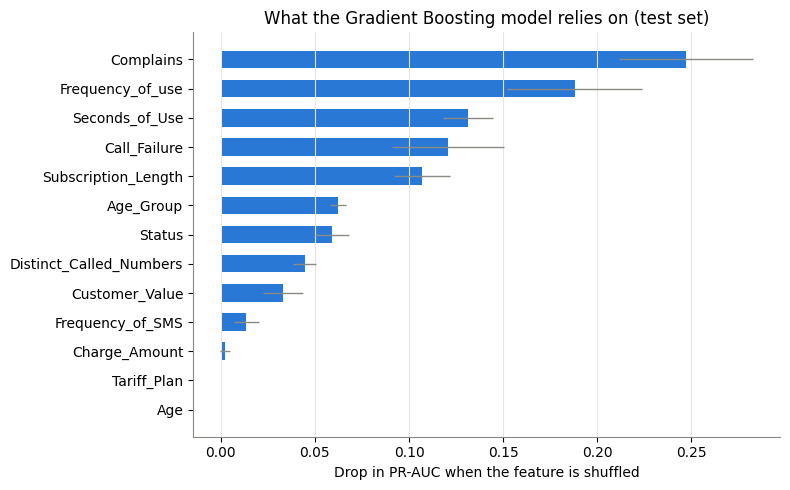

In [14]:
# Part 8.1: Permutation importance on the test set
result = permutation_importance(best_model, X_test, y_test, scoring="average_precision",
                                n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(result.importances_mean, index=X_test.columns)
spread = pd.Series(result.importances_std, index=X_test.columns)
order = importance.sort_values().index      # smallest first -> biggest ends up on top

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(order, importance[order], xerr=spread[order], color=BLUE, height=0.6,
        error_kw={"ecolor": GREY, "elinewidth": 1})
ax.set_xlabel("Drop in PR-AUC when the feature is shuffled")
ax.set_title(f"What the {best_name} model relies on (test set)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig("figures/permutation_importance.png", dpi=150)
plt.show()

### 8.2 Reality check with plain pandas
Models can be wrong, so we check the top signals directly in the data with `groupby`.

**Python note:** `df.groupby("Complains")["Churn"].mean()` means: *split the customers into groups by `Complains` (0 or 1), then take the average of `Churn` in each group*. Because Churn is 0/1, the average is the **churn rate of each group**.

`pd.qcut(..., q=4)` splits a number column into **4 equal-sized groups** (quartiles), so we can see the churn rate from low to high usage. `observed=True` hides empty groups and avoids a pandas warning.

In [15]:
# Part 8.2: Churn rate by group, using the training set only
train_df = X_train.assign(Churn=y_train)      # put features and target back together

print("Churn rate by complaint (0 = no, 1 = yes):")
print(train_df.groupby("Complains")["Churn"].mean().round(3), "\n")

print("Churn rate by usage quartile (Frequency_of_use):")
usage_quartile = pd.qcut(train_df["Frequency_of_use"], q=4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
print(train_df.groupby(usage_quartile, observed=True)["Churn"].mean().round(3))

Churn rate by complaint (0 = no, 1 = yes):
Complains
0    0.100
1    0.813
Name: Churn, dtype: float64 

Churn rate by usage quartile (Frequency_of_use):
Frequency_of_use
Q1 lowest     0.320
Q2            0.214
Q3            0.073
Q4 highest    0.014
Name: Churn, dtype: float64


**Business reading (association, not proof of cause):** customers who **complained** churn about **8× more often** (81% vs 10%), and the lowest-usage quarter churns at **32%** vs about **1%** for the heaviest users. A retention team could act on this: contact customers who complained, and watch for drops in usage, before month 12.

## Part 9: Summary and limitations
### What changed
| | Original | Improved |
|---|---|---|
| Model | Logistic Regression | Gradient Boosting (chosen by 5-fold CV) |
| Threshold | 0.5 (default) | tuned on training CV (max F1) |
| Main metric | accuracy | PR-AUC + recall/precision |
| Churners missed (of 89) | 46 | 8 |

### What I learned
1. **Accuracy is misleading with imbalanced data.** A do-nothing model already gets 84%.
2. **Class weights and thresholds move along a trade-off; a better model moves the whole curve.**
3. **Correlated features make coefficients unreliable**, even when predictions are fine.
4. **Make every choice on training data (cross-validation) and use the test set once.**

### Limitations
- One Iranian telecom operator over one year. Other companies and markets may behave differently.
- The test set is small (89 churners), so results have some uncertainty (±a few points).
- `Customer_Value` is not explained in the dataset documentation.
- The threshold rule (max F1) is a neutral choice. A real company should set it using the real costs of a missed churner vs a retention offer.
- The importance results show **association, not cause**.
- Default hyperparameters were used. Tuning could add a little, but the main gains came from the model type and the threshold.

## Part 10: Your turn
Do these yourself (no AI), then explain what changed and **why**.

**A. Small project changes (pick 1–2):**
1. **Business rule threshold:** in Part 6, instead of the best F1, choose the threshold with **the best precision while recall ≥ 0.95**.
   *Hint:* `ok = np.where(recall[:-1] >= 0.95)[0]` gives the positions that meet the rule; then pick the one with the highest `precision`. What happens to false alarms?
2. **Drop `Complains`** from the features and re-run Parts 5–7. How much does PR-AUC fall? What does that tell you?
3. In Part 5, change `n_estimators=300` to `50` for Random Forest. Does it change much? Why might more trees help?

**B. Python exercises (5–10 min each):**
1. Print how many churners are in `y_test` and what percentage that is (two ways: `.sum()` / `len()`, and `.mean()`).
2. Using `groupby`, find the churn rate for each `Tariff_Plan` (1 = pay as you go, 2 = contractual).
3. Write a function `churn_rate_by(column)` that prints the churn rate for each value of any column, then call it for `Status` and `Age_Group`.